In [1]:
# Imports
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import ToTensor, Lambda

In [ ]:
# Download the MNIST dataset

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.5,), (0.5,))
                               ])
mnist_train_dataset = datasets.MNIST(root='/home/savio/Documents/modeling_generation/data', train=True, download=True, transform=transform)
mnist_eval_dataset = datasets.MNIST(root='/home/savio/Documents/modeling_generation/data', train=False, download=True, transform=transform)

# Get a sample image from the training dataset so we can get its shape for our model
sample_img, _ = mnist_train_dataset[0]
print(f"Sample image shape: {sample_img.shape}")  # Should be (1, 28, 28) for MNIST

Sample image shape: torch.Size([1, 28, 28])


In [3]:
# Create data loaders
batch_size = 32
train_loader = DataLoader(mnist_train_dataset, batch_size=batch_size, shuffle=True)
eval_loader = DataLoader(mnist_eval_dataset, batch_size=batch_size, shuffle=False)

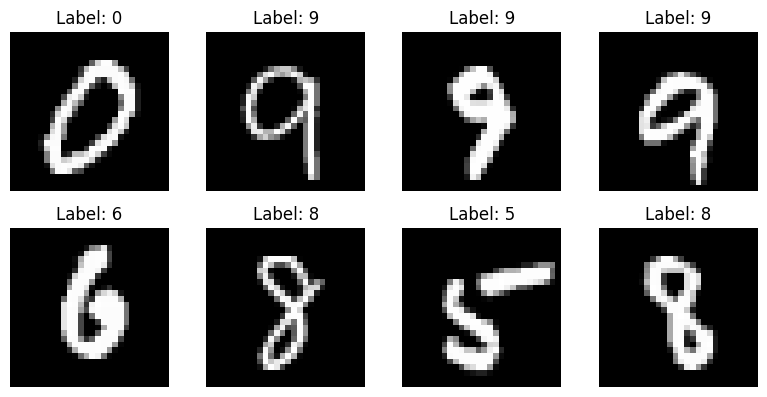

In [4]:
# Plot a few sample images from the training dataset
import matplotlib.pyplot as plt

def plot_samples(data_loader, num_samples=8):
    images, labels = next(iter(data_loader))
    plt.figure(figsize=(8, 8))
    for i in range(num_samples):
        plt.subplot(4, 4, i + 1)
        plt.imshow(images[i].squeeze(), cmap='gray')
        plt.title(f"Label: {labels[i].item()}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

plot_samples(train_loader)

In [5]:
# Set the device for training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


/home/savio/anaconda3/envs/gen_modeling/lib/python3.11/site-packages/torch/cuda/__init__.py:182: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [6]:
## Create the neural network to be used as the energy function
from cnn_energy import CNNEnergy

energy_function = CNNEnergy(num_channels_first_layer=16)
energy_function.to(device)

CNNEnergy(
  (conv_layers): Sequential(
    (0): Conv2d(1, 16, kernel_size=(5, 5), stride=(2, 2), padding=(4, 4))
    (1): Swish()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): Swish()
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): Swish()
    (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): Swish()
  )
  (linear_layers): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): Swish()
    (2): Linear(in_features=128, out_features=1, bias=True)
  )
)

In [7]:
## Create the sampler class
from sampler import LangevinSampler

sampler = LangevinSampler(energy_function=energy_function, img_shape=sample_img.shape, batch_size=batch_size)

In [8]:
## Setup the optimizer for training the energy function
optimizer = torch.optim.Adam(energy_function.parameters(), lr=3e-4)

In [9]:
## Training loop
num_epochs = 10
reg_lambda = 0.1  # Regularization loss weighting parameter. You can tune this hyperparameter to balance the two terms in the loss

cdviv_losses = []
reg_losses = []
total_losses = []

for epoch in range(num_epochs):
    energy_function.train()
    epoch_loss = 0.0
    
    for batch_idx, (real_imgs, _) in enumerate(train_loader):
        real_imgs = real_imgs.to(next(energy_function.parameters()).device)  # Move to the same device as the model
        
        # Sample negative examples using Langevin dynamics
        fake_imgs = sampler.sample_new_exmps(steps=60, step_size=10)
        
        # Compute energies for real and sampled images
        real_energies = energy_function(real_imgs)
        fake_energies = energy_function(fake_imgs)
        
        # Compute the loss (we want to minimize energy of real images and maximize energy of sampled images)
        cdiv_loss = real_energies.mean() - fake_energies.mean()
        
        # Add regularization term to the loss to keep the energy values from diverging too much
        reg_loss = reg_lambda * (real_energies.pow(2) + fake_energies.pow(2)).mean()

        # Total loss is the contrastive divergence loss plus the regularization loss
        loss = cdiv_loss + reg_loss

        # Backpropagation and optimization step
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()

        cdviv_losses.append(cdiv_loss.item())
        reg_losses.append(reg_loss.item())
        total_losses.append(loss.item())
    
    avg_loss = epoch_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}")

Epoch [1/10], Loss: -3.7933
Epoch [2/10], Loss: -4.1465
Epoch [3/10], Loss: -4.6308
Epoch [4/10], Loss: -4.7186
Epoch [5/10], Loss: -4.7790
Epoch [6/10], Loss: -4.7247
Epoch [7/10], Loss: -4.8662
Epoch [8/10], Loss: -4.9090
Epoch [9/10], Loss: -4.9094
Epoch [10/10], Loss: -4.9270


In [10]:
# Save the model weights in a ckpt file
torch.save(energy_function.state_dict(), "cnn_energy_mnist_gen_ep_10.ckpt")

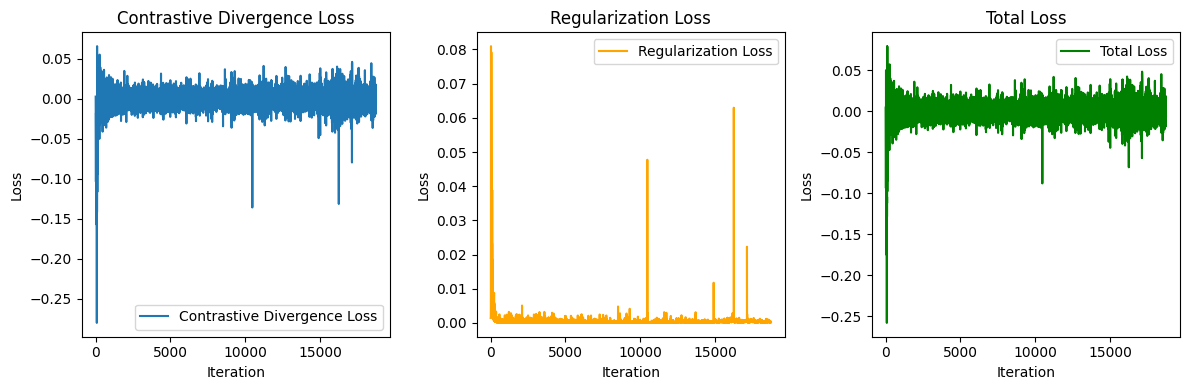

In [11]:
# Plot the losses
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.plot(cdviv_losses, label='Contrastive Divergence Loss')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Contrastive Divergence Loss')
plt.legend()    
plt.subplot(1, 3, 2)
plt.plot(reg_losses, label='Regularization Loss', color='orange')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Regularization Loss')
plt.legend()
plt.subplot(1, 3, 3)
plt.plot(total_losses, label='Total Loss', color='green')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Total Loss')
plt.legend()
plt.tight_layout()
plt.show()

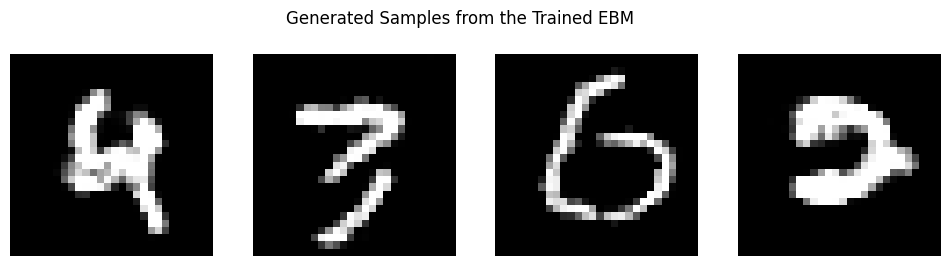

In [33]:
# Generate some samples from the trained model

# First create a few random noise images to initialize the sampling process, 
# then run the sampler for a number of steps to get new samples from the model.
eval_batch_size = 4
noise_imgs = torch.rand((eval_batch_size,) + sample_img.shape, device=device) * 2 - 1  # Random noise in [-1, 1]

# Get some samples from the eval dataset and add noise to them, then run the sampler starting from these noisy real images. This can sometimes lead to better samples than starting from pure noise.
# real_eval_imgs, _ = next(iter(eval_loader))
# real_eval_imgs = real_eval_imgs[0:eval_batch_size].to(device)
# noise_imgs = real_eval_imgs + (torch.rand_like(real_eval_imgs) * 1.5 - 0.25)  # Add some noise to the real images

with torch.no_grad():
    generated_samples = LangevinSampler.generate_samples(energy_function, noise_imgs, steps=500, step_size=10)

# Visualize the generated samples
generated_samples = generated_samples.detach().cpu().numpy()  # Move to CPU and convert to numpy for plotting
generated_samples = (generated_samples + 1) / 2  # Scale back to [0, 1] for visualization
fig, axes = plt.subplots(1, eval_batch_size, figsize=(12, 3))
for i in range(eval_batch_size):
    axes[i].imshow(generated_samples[i][0], cmap='gray')  # Show the first channel (grayscale)
    axes[i].axis('off')
plt.suptitle('Generated Samples from the Trained EBM')
plt.show()